# CIFAR-10 / ResNet-20 
# Train all layers; use RMS scaling for Muon and Spectral optimizers

In [6]:
from stepback.plot_utils import load_sweep, plot_val_acc_vs_lr, plot_val_acc_vs_epoch
import pandas as pd

In [2]:
R = load_sweep("cifar10_resnet20_compare")
R.id_df

/mnt/home/tparshakova/Documents/step-back/stepback/record.py:67: UserWarning: Loading from multiple output files. Contents will be merged.
  warnings.warn("Loading from multiple output files. Contents will be merged.")


Creating Record with ID cifar10_resnet20_compare-000.
Loading data from output/cifar10_resnet20_compare-000
Loading data from output/cifar10_resnet20_compare-001
Loading data from output/cifar10_resnet20_compare-002
Loading data from output/cifar10_resnet20_compare-003
Loading data from output/cifar10_resnet20_compare-004
Loading data from output/cifar10_resnet20_compare-005
Loading data from output/cifar10_resnet20_compare-006
Loading data from output/cifar10_resnet20_compare-007
Loading data from output/cifar10_resnet20_compare-008
Loading data from output/cifar10_resnet20_compare-009
Loading data from output/cifar10_resnet20_compare-010
Loading data from output/cifar10_resnet20_compare-011
Loading data from output/cifar10_resnet20_compare-012
Loading data from output/cifar10_resnet20_compare-013
Loading data from output/cifar10_resnet20_compare-014
Loading data from output/cifar10_resnet20_compare-015
Loading data from output/cifar10_resnet20_compare-016
Loading data from output/cif

,name,lr,lr_schedule,momentum,ns_steps,weight_decay,dampening
name=muon:lr=0.0001:lr_schedule=constant:momentum=0.95:ns_steps=5:weight_decay=0,muon,0.0001,constant,0.95,5,0,none
name=muon:lr=0.0003:lr_schedule=constant:momentum=0.95:ns_steps=5:weight_decay=0,muon,0.0003,constant,0.95,5,0,none
name=muon:lr=0.001:lr_schedule=constant:momentum=0.95:ns_steps=5:weight_decay=0,muon,0.001,constant,0.95,5,0,none
name=muon:lr=0.003:lr_schedule=constant:momentum=0.95:ns_steps=5:weight_decay=0,muon,0.003,constant,0.95,5,0,none
name=muon:lr=0.01:lr_schedule=constant:momentum=0.95:ns_steps=5:weight_decay=0,muon,0.01,constant,0.95,5,0,none
name=spectral-clip:lr=0.0001:lr_schedule=constant:momentum=0.95:weight_decay=0,spectral-clip,0.0001,constant,0.95,none,0,none
name=spectral-clip:lr=0.0003:lr_schedule=constant:momentum=0.95:weight_decay=0,spectral-clip,0.0003,constant,0.95,none,0,none
name=spectral-clip:lr=0.001:lr_schedule=constant:momentum=0.95:weight_decay=0,spectral-clip,0.001,constant,0.95,none,0,none
name=spectral-clip:lr=0.003:lr_schedule=constant:momentum=0.95:weight_decay=0,spectral-clip,0.003,constant,0.95,none,0,none
name=spectral-clip:lr=0.01:lr_schedule=constant:momentum=0.95:weight_decay=0,spectral-clip,0.01,constant,0.95,none,0,none


/mnt/home/tparshakova/Documents/step-back/stepback/record.py:260: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cutoff_epoch = (max_epoch[0], max_epoch[0])


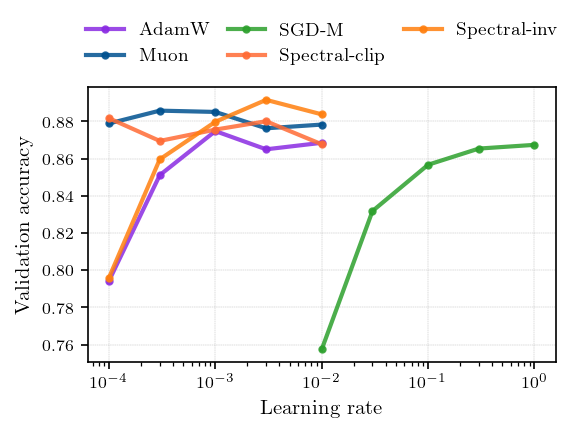

In [3]:
fig, ax = plot_val_acc_vs_lr(R, filename="output/cifar10_resnet20_val_acc_vs_lr.pdf")

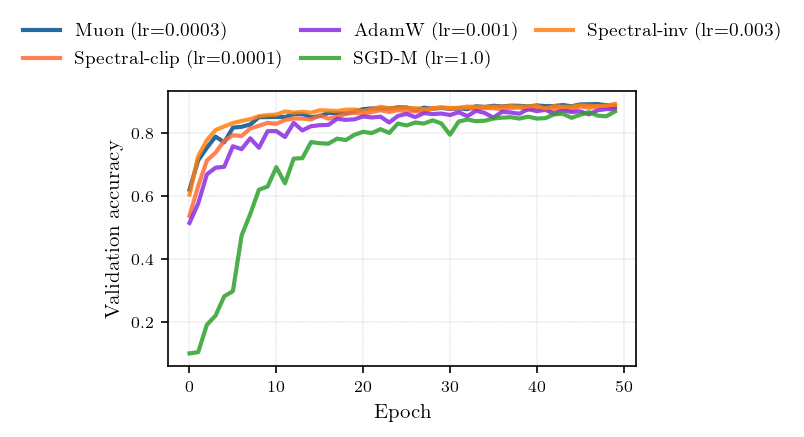

In [4]:
fig, ax = plot_val_acc_vs_epoch(R)

In [7]:
# ── Best config per method: val accuracy & val loss ──
from stepback.plot_utils import _display_name

rows = []
for name in R.id_df["name"].unique():
    sub = R.base_df[R.base_df["name"] == name]
    final = sub[sub["epoch"] == sub["epoch"].max()]
    best_row = final.loc[final["val_score"].idxmax()]
    conf = dict(item.split("=") for item in best_row["id"].split(":"))
    rows.append({
        "Method": _display_name(name),
        "lr": float(conf["lr"]),
        "Val Acc": f'{best_row["val_score"]:.4f}',
        "Val Loss": f'{best_row["val_loss"]:.4f}',
    })

table = pd.DataFrame(rows).sort_values("Val Acc", ascending=False).reset_index(drop=True)
table

,Method,lr,Val Acc,Val Loss
0,Spectral-inv,0.0030,0.8916,0.4151
1,Muon,0.0003,0.8858,0.4779
2,Spectral-clip,0.0001,0.8817,0.4383
3,AdamW,0.0010,0.8748,0.4460
4,SGD-M,1.0000,0.8674,0.4204
